# Smart Traffic Intelligence System
## Phase 5: Accident Severity Prediction Using Machine Learning

### Project Objective
To develop machine learning models that predict the severity category of road accidents using historical accident information.

### Dataset
NYC Motor Vehicle Collisions - Crashes

### Severity Categories
1. Property Damage
2. Injury
3. Fatal

### Machine Learning Algorithms
- Random Forest Classifier
- XGBoost Classifier (optional, if installed)

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- Macro F1-Score
- Confusion Matrix

### Important Note
Injury and death counts are used only to create the target variable.
They are excluded from model input features to prevent data leakage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import json

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "dataset").exists():
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_PATH = PROJECT_DIR / "dataset" / "raw" / "traffic_accidents.csv"

MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "visualizations" / "reports"
CHART_DIR = PROJECT_DIR / "visualizations" / "charts"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset path:", RAW_DATA_PATH)
print("Dataset available:", RAW_DATA_PATH.exists())

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        "traffic_accidents.csv not found inside dataset/raw/"
    )

Project directory: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project
Dataset path: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\dataset\raw\traffic_accidents.csv
Dataset available: True


In [3]:
def normalize_column_name(column):
    return (
        str(column)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


original_columns = pd.read_csv(
    RAW_DATA_PATH,
    nrows=0
).columns.tolist()

column_lookup = {
    normalize_column_name(col): col
    for col in original_columns
}

column_candidates = {
    "crash_date": ["crash_date"],
    "crash_time": ["crash_time"],
    "borough": ["borough"],
    "zip_code": ["zip_code"],
    "injured": ["number_of_persons_injured"],
    "killed": ["number_of_persons_killed"],
    "factor": [
        "contributing_factor_vehicle_1",
        "contributing_factor_vehicle1"
    ],
    "vehicle": [
        "vehicle_type_code1",
        "vehicle_type_code_1"
    ]
}

selected_columns = {}

for key, candidates in column_candidates.items():
    for candidate in candidates:
        if candidate in column_lookup:
            selected_columns[key] = column_lookup[candidate]
            break

required_columns = [
    "crash_date",
    "crash_time",
    "injured",
    "killed"
]

missing_required = [
    col for col in required_columns
    if col not in selected_columns
]

print("Original dataset columns:")
print(original_columns)

print("\nSelected columns:")
print(selected_columns)

if missing_required:
    raise ValueError(
        f"Required dataset columns are missing: {missing_required}"
    )

print("\nDataset column verification completed!")

Original dataset columns:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']

Selected columns:
{'crash_date': 'CRASH DATE', 'crash_time': 'CRASH TIME', 'borough': 'BOROUGH', 'zip_code': 'ZIP CODE', 'injured': 'NUMBER OF PERSONS INJURED', 'killed': 'NUMBER OF PERSONS KILLED', 'factor': 'CONTRIBUTING FACTOR VEHICLE 1', 'vehicle': 'VEHICLE TYPE CODE 1'}

Dataset column 

In [4]:
use_columns = list(dict.fromkeys(selected_columns.values()))

df = pd.read_csv(
    RAW_DATA_PATH,
    usecols=use_columns,
    low_memory=False
)

reverse_lookup = {
    original: key
    for key, original in selected_columns.items()
}

df.rename(columns=reverse_lookup, inplace=True)

print("=" * 60)
print("ACCIDENT DATASET LOADED")
print("=" * 60)

print("Total records:", len(df))
print("Total selected columns:", len(df.columns))

display(df.head())

print("\nDataset information:")
df.info()

ACCIDENT DATASET LOADED
Total records: 2301644
Total selected columns: 8


,crash_date,crash_time,borough,zip_code,injured,killed,factor,vehicle
0,10/27/2026,15:48,MANHATTAN,10013.0,0.0,0.0,Does Not Apply,4 dr sedan
1,10/27/2026,23:54,BROOKLYN,11219.0,0.0,0.0,Does Not Apply,Station Wagon/Sport Utility Vehicle
2,10/27/2026,12:35,QUEENS,11433.0,2.0,0.0,Driver Inattention/Distraction,4 dr sedan
3,10/27/2026,07:35,BRONX,NaN,0.0,0.0,Does Not Apply,4 dr sedan
4,10/27/2026,15:53,MANHATTAN,10034.0,0.0,0.0,Does Not Apply,Bus (Omnibus)



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2301644 entries, 0 to 2301643
Data columns (total 8 columns):
 #   Column      Dtype  
---  ------      -----  
 0   crash_date  str    
 1   crash_time  str    
 2   borough     str    
 3   zip_code    float64
 4   injured     float64
 5   killed      float64
 6   factor      str    
 7   vehicle     str    
dtypes: float64(3), str(5)
memory usage: 140.5 MB


In [5]:
# Convert injury and death counts to numeric values
df["injured"] = pd.to_numeric(
    df["injured"],
    errors="coerce"
).fillna(0)

df["killed"] = pd.to_numeric(
    df["killed"],
    errors="coerce"
).fillna(0)

# Negative counts are not valid
df = df[
    (df["injured"] >= 0) &
    (df["killed"] >= 0)
].copy()

# Create severity categories
conditions = [
    df["killed"] > 0,
    df["injured"] > 0
]

choices = [
    "Fatal",
    "Injury"
]

df["severity"] = np.select(
    conditions,
    choices,
    default="Property Damage"
)

print("Severity labels created successfully!")

print("\nSeverity distribution:")
severity_counts = df["severity"].value_counts()

display(
    severity_counts.rename("Accident Count").to_frame()
)

print("\nTotal records:", len(df))

Severity labels created successfully!

Severity distribution:


,Accident Count
severity,
Property Damage,1725037
Injury,573026
Fatal,3581



Total records: 2301644


In [6]:
# Convert accident date
df["crash_date"] = pd.to_datetime(
    df["crash_date"],
    format="mixed",
    errors="coerce"
)

# Extract accident hour from crash_time
df["crash_hour"] = pd.to_numeric(
    df["crash_time"]
    .astype(str)
    .str.extract(r"^\s*(\d{1,2})")[0],
    errors="coerce"
)

# Extract date-based features
df["crash_year"] = df["crash_date"].dt.year
df["crash_month"] = df["crash_date"].dt.month
df["day_of_week"] = df["crash_date"].dt.dayofweek

# Cyclical time features
df["hour_sin"] = np.sin(
    2 * np.pi * df["crash_hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["crash_hour"] / 24
)

df["month_sin"] = np.sin(
    2 * np.pi * df["crash_month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["crash_month"] / 12
)

print("Feature engineering completed!")

display(
    df[
        [
            "crash_date",
            "crash_time",
            "crash_hour",
            "crash_year",
            "crash_month",
            "day_of_week",
            "hour_sin",
            "hour_cos",
            "severity"
        ]
    ].head(10)
)

Feature engineering completed!


,crash_date,crash_time,crash_hour,crash_year,crash_month,day_of_week,hour_sin,hour_cos,severity
0,2026-10-27,15:48,15,2026,10,1,-7.071068e-01,-7.071068e-01,Property Damage
1,2026-10-27,23:54,23,2026,10,1,-2.588190e-01,9.659258e-01,Property Damage
2,2026-10-27,12:35,12,2026,10,1,1.224647e-16,-1.000000e+00,Injury
3,2026-10-27,07:35,7,2026,10,1,9.659258e-01,-2.588190e-01,Property Damage
4,2026-10-27,15:53,15,2026,10,1,-7.071068e-01,-7.071068e-01,Property Damage
5,2026-10-27,18:20,18,2026,10,1,-1.000000e+00,-1.836970e-16,Injury
6,2026-10-27,11:32,11,2026,10,1,2.588190e-01,-9.659258e-01,Property Damage
7,2026-10-27,01:34,1,2026,10,1,2.588190e-01,9.659258e-01,Injury
8,2026-10-27,15:28,15,2026,10,1,-7.071068e-01,-7.071068e-01,Property Damage
9,2026-10-27,15:30,15,2026,10,1,-7.071068e-01,-7.071068e-01,Injury


In [7]:
# Numerical input features
numeric_features = [
    "crash_hour",
    "crash_year",
    "crash_month",
    "day_of_week",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos"
]

# Categorical input features
categorical_features = [
    col for col in [
        "borough",
        "zip_code",
        "factor",
        "vehicle"
    ]
    if col in df.columns
]

feature_columns = numeric_features + categorical_features

# Ensure numerical columns are numeric
for column in numeric_features:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Ensure categorical columns are strings
for column in categorical_features:
    df[column] = (
        df[column]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

# Keep only valid target and required feature columns
model_df = df[feature_columns + ["severity"]].copy()

model_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

model_df.dropna(
    subset=["severity"],
    inplace=True
)

X = model_df[feature_columns].copy()
y = model_df["severity"].copy()

print("Model feature preparation completed!")

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nInput feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().to_frame("Records"))

print("\nLeakage check:")
print("Injury count included:", "injured" in X.columns)
print("Death count included:", "killed" in X.columns)

Model feature preparation completed!

Numerical features:
['crash_hour', 'crash_year', 'crash_month', 'day_of_week', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']

Categorical features:
['borough', 'zip_code', 'factor', 'vehicle']

Input feature shape: (2301644, 12)
Target shape: (2301644,)

Target distribution:


,Records
severity,
Property Damage,1725037
Injury,573026
Fatal,3581



Leakage check:
Injury count included: False
Death count included: False


In [8]:
MAX_RECORDS = 200000

class_counts = y.value_counts()

print("Original severity counts:")
display(class_counts.to_frame("Records"))

if len(class_counts) < 2:
    raise ValueError(
        "At least two severity categories are required for classification."
    )

if class_counts.min() < 2:
    raise ValueError(
        "A severity category has fewer than two records. "
        "A stratified train-test split cannot be performed reliably."
    )

if len(X) > MAX_RECORDS:

    sampled_parts = []

    for severity_name, group in model_df.groupby("severity"):

        proportion = len(group) / len(model_df)

        sample_count = max(
            2,
            int(round(MAX_RECORDS * proportion))
        )

        sample_count = min(
            sample_count,
            len(group)
        )

        sampled_parts.append(
            group.sample(
                n=sample_count,
                random_state=42
            )
        )

    sample_df = pd.concat(
        sampled_parts,
        ignore_index=True
    )

    # If rounding makes the sample slightly larger than the limit,
    # reduce the largest class while preserving at least two samples.
    while len(sample_df) > MAX_RECORDS:

        counts = sample_df["severity"].value_counts()

        removable_classes = counts[counts > 2]

        if removable_classes.empty:
            break

        largest_class = removable_classes.idxmax()

        index_to_remove = sample_df[
            sample_df["severity"] == largest_class
        ].sample(
            n=1,
            random_state=42
        ).index

        sample_df = sample_df.drop(index_to_remove)

else:
    sample_df = model_df.copy()

sample_df = sample_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

X = sample_df[feature_columns].copy()
y = sample_df["severity"].copy()

print("Records selected for training:", len(X))

print("\nSelected severity distribution:")
display(y.value_counts().to_frame("Records"))

Original severity counts:


,Records
severity,
Property Damage,1725037
Injury,573026
Fatal,3581


Records selected for training: 200000

Selected severity distribution:


,Records
severity,
Property Damage,149896
Injury,49793
Fatal,311


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 55)
print("TRAINING AND TESTING DATA SPLIT")
print("=" * 55)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("Records"))

print("\nTesting class distribution:")
display(y_test.value_counts().to_frame("Records"))

TRAINING AND TESTING DATA SPLIT
Training records: 160000
Testing records: 40000

Training class distribution:


,Records
severity,
Property Damage,119917
Injury,39834
Fatal,249



Testing class distribution:


,Records
severity,
Property Damage,29979
Injury,9959
Fatal,62


In [10]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [11]:
random_forest = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest training started...")

random_forest.fit(
    X_train,
    y_train
)

print("\nRandom Forest training completed successfully!")

rf_predictions = random_forest.predict(X_test)

print("\nRandom Forest predictions generated!")

Random Forest training started...

Random Forest training completed successfully!

Random Forest predictions generated!


In [12]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_precision = precision_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Macro Precision": rf_precision,
    "Macro Recall": rf_recall,
    "Macro F1-Score": rf_f1
}

print("=" * 55)
print("RANDOM FOREST MODEL EVALUATION")
print("=" * 55)

for metric, value in rf_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

RANDOM FOREST MODEL EVALUATION
Accuracy: 0.6915
Macro Precision: 0.4253
Macro Recall: 0.4558
Macro F1-Score: 0.4328

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.03      0.08      0.04        62
         Injury       0.41      0.55      0.47      9959
Property Damage       0.83      0.74      0.78     29979

       accuracy                           0.69     40000
      macro avg       0.43      0.46      0.43     40000
   weighted avg       0.73      0.69      0.70     40000



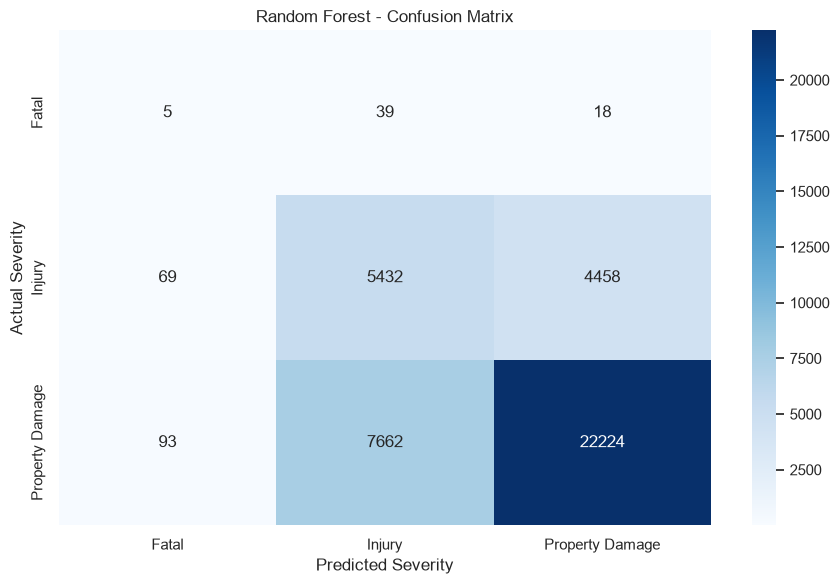

In [13]:
class_labels = sorted(y.unique())

rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=class_labels
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

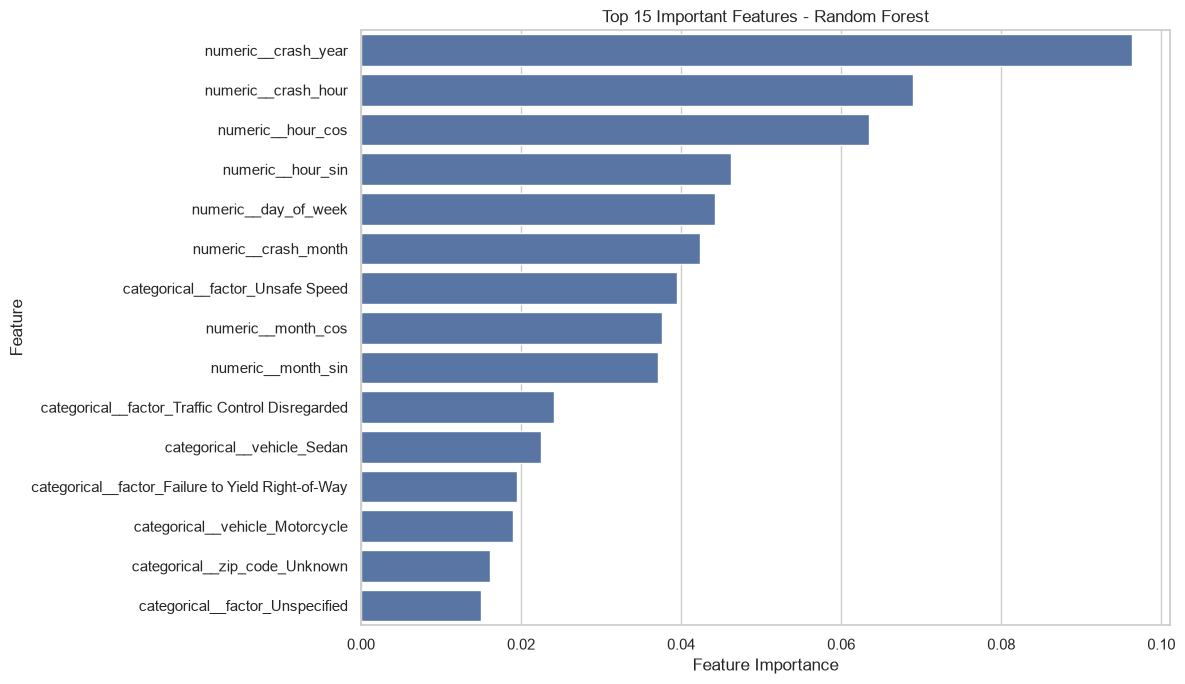

,Feature,Importance
1,numeric__crash_year,0.096292
0,numeric__crash_hour,0.068949
5,numeric__hour_cos,0.063446
4,numeric__hour_sin,0.046291
3,numeric__day_of_week,0.044283
2,numeric__crash_month,0.042306
244,categorical__factor_Unsafe Speed,0.039515
7,numeric__month_cos,0.037595
6,numeric__month_sin,0.037070
240,categorical__factor_Traffic Control Disregarded,0.024170


In [14]:
trained_preprocessor = random_forest.named_steps["preprocessor"]

trained_classifier = random_forest.named_steps["classifier"]

encoded_feature_names = (
    trained_preprocessor.get_feature_names_out()
)

importance_df = pd.DataFrame(
    {
        "Feature": encoded_feature_names,
        "Importance": trained_classifier.feature_importances_
    }
)

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(top_features)

In [15]:
xgb_model = None
xgb_predictions = None
xgb_results = None

try:
    from xgboost import XGBClassifier

    # Encode target labels for XGBoost
    target_mapping = {
        label: index
        for index, label in enumerate(class_labels)
    }

    reverse_target_mapping = {
        index: label
        for label, index in target_mapping.items()
    }

    y_train_encoded = y_train.map(target_mapping)
    y_test_encoded = y_test.map(target_mapping)

    xgb_model = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                XGBClassifier(
                    objective="multi:softprob",
                    num_class=len(class_labels),
                    n_estimators=150,
                    max_depth=6,
                    learning_rate=0.08,
                    subsample=0.85,
                    colsample_bytree=0.85,
                    eval_metric="mlogloss",
                    tree_method="hist",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    print("XGBoost training started...")

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )

    xgb_model.fit(
        X_train,
        y_train_encoded,
        classifier__sample_weight=sample_weights
    )

    encoded_predictions = xgb_model.predict(X_test)

    xgb_predictions = pd.Series(
        encoded_predictions
    ).map(reverse_target_mapping).to_numpy()

    xgb_results = {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(
            y_test,
            xgb_predictions
        ),
        "Macro Precision": precision_score(
            y_test,
            xgb_predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test,
            xgb_predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1-Score": f1_score(
            y_test,
            xgb_predictions,
            average="macro",
            zero_division=0
        )
    }

    print("\nXGBoost training completed successfully!")

    print("\nXGBoost Classification Report:")
    print(
        classification_report(
            y_test,
            xgb_predictions,
            zero_division=0
        )
    )

except ImportError:
    print(
        "XGBoost is not installed. "
        "Random Forest results are available."
    )

except Exception as error:
    print("XGBoost could not be trained.")
    print("Reason:", error)
    print("Random Forest results remain available.")
    

XGBoost is not installed. Random Forest results are available.


MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.6915,0.4253,0.4558,0.4328


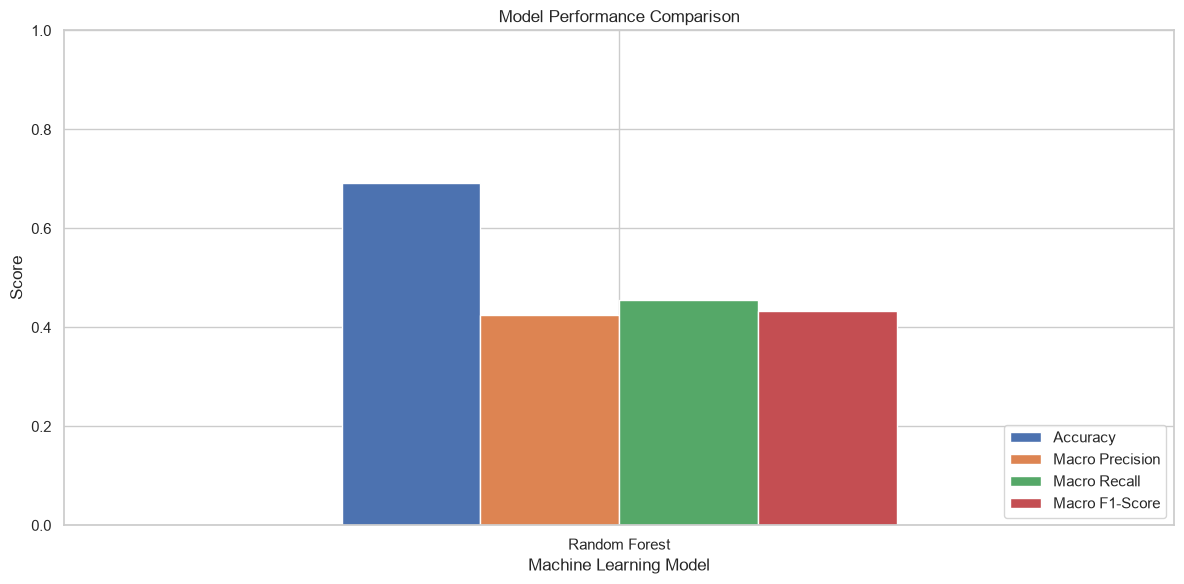

In [16]:
results_list = [rf_results]

if xgb_results is not None:
    results_list.append(xgb_results)

comparison_df = pd.DataFrame(results_list)

print("=" * 65)
print("MACHINE LEARNING MODEL COMPARISON")
print("=" * 65)

display(
    comparison_df.style.format(
        {
            "Accuracy": "{:.4f}",
            "Macro Precision": "{:.4f}",
            "Macro Recall": "{:.4f}",
            "Macro F1-Score": "{:.4f}"
        }
    )
)

comparison_df.set_index("Model")[
    [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Save Random Forest pipeline
rf_model_path = MODEL_DIR / "accident_severity_random_forest.pkl"

joblib.dump(
    random_forest,
    rf_model_path
)

# Save XGBoost pipeline if successfully trained
if xgb_model is not None and xgb_results is not None:
    xgb_model_path = MODEL_DIR / "accident_severity_xgboost.pkl"

    joblib.dump(
        xgb_model,
        xgb_model_path
    )

# Save model comparison
comparison_path = REPORT_DIR / "model_comparison.csv"

comparison_df.to_csv(
    comparison_path,
    index=False
)

# Save feature importance
importance_path = REPORT_DIR / "feature_importance.csv"

importance_df.to_csv(
    importance_path,
    index=False
)

# Save model configuration
model_metadata = {
    "project": "Smart Traffic Intelligence System",
    "target": "severity",
    "severity_categories": class_labels,
    "numerical_features": numeric_features,
    "categorical_features": categorical_features,
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "random_forest_metrics": {
        key: float(value)
        for key, value in rf_results.items()
        if key != "Model"
    }
}

with open(
    REPORT_DIR / "model_metadata.json",
    "w"
) as file:
    json.dump(
        model_metadata,
        file,
        indent=4
    )

print("All model files and reports saved successfully!")

print("\nSaved files:")
print(rf_model_path)
print(comparison_path)
print(importance_path)
print(REPORT_DIR / "model_metadata.json")

All model files and reports saved successfully!

Saved files:
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\models\accident_severity_random_forest.pkl
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\reports\model_comparison.csv
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\reports\feature_importance.csv
c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\reports\model_metadata.json


In [18]:
sample_accident = X_test.iloc[[0]].copy()

actual_severity = y_test.iloc[0]

predicted_severity = random_forest.predict(
    sample_accident
)[0]

prediction_probabilities = random_forest.predict_proba(
    sample_accident
)[0]

probability_df = pd.DataFrame(
    {
        "Severity": random_forest.classes_,
        "Probability": prediction_probabilities
    }
).sort_values(
    by="Probability",
    ascending=False
)

print("=" * 60)
print("ACCIDENT SEVERITY PREDICTION DEMONSTRATION")
print("=" * 60)

print("\nInput accident information:")
display(sample_accident)

print("Actual severity:", actual_severity)
print("Predicted severity:", predicted_severity)

print("\nPrediction probabilities:")
display(probability_df)

ACCIDENT SEVERITY PREDICTION DEMONSTRATION

Input accident information:


,crash_hour,crash_year,crash_month,day_of_week,hour_sin,hour_cos,month_sin,month_cos,borough,zip_code,factor,vehicle
74134,12,2016,9,5,1.224647e-16,-1.0,-1.0,-1.836970e-16,Unknown,Unknown,Driver Inexperience,Station Wagon/Sport Utility Vehicle


Actual severity: Property Damage
Predicted severity: Property Damage

Prediction probabilities:


,Severity,Probability
2,Property Damage,0.494757
1,Injury,0.381688
0,Fatal,0.123555


In [19]:
print("\n" + "=" * 65)
print("SMART TRAFFIC INTELLIGENCE SYSTEM")
print("PHASE 5: ACCIDENT SEVERITY PREDICTION")
print("=" * 65)

print("Dataset records used:", len(sample_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nSeverity categories:")
for category in class_labels:
    print("-", category)

print("\nRandom Forest Performance:")
print(f"Accuracy: {rf_accuracy:.4f}")
print(f"Macro Precision: {rf_precision:.4f}")
print(f"Macro Recall: {rf_recall:.4f}")
print(f"Macro F1-Score: {rf_f1:.4f}")

print("\nXGBoost available:", xgb_results is not None)

print("\nModel saved:", rf_model_path.exists())
print("Reports directory:", REPORT_DIR)
print("Charts directory:", CHART_DIR)

print("\nPHASE 5 COMPLETED SUCCESSFULLY!")
print("=" * 65)


SMART TRAFFIC INTELLIGENCE SYSTEM
PHASE 5: ACCIDENT SEVERITY PREDICTION
Dataset records used: 200000
Training records: 160000
Testing records: 40000

Severity categories:
- Fatal
- Injury
- Property Damage

Random Forest Performance:
Accuracy: 0.6915
Macro Precision: 0.4253
Macro Recall: 0.4558
Macro F1-Score: 0.4328

XGBoost available: False

Model saved: True
Reports directory: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\reports
Charts directory: c:\Users\Pavan Naik\OneDrive\Desktop\DSV-project\visualizations\charts

PHASE 5 COMPLETED SUCCESSFULLY!
